# Cluster

## Objectives

* Fit and evaluate a cluster model to group similar data
* Understand the profile for each cluster


## Inputs

* outputs/datasets/collection/Heart_failure_record_dataset.csv
* Instructions on which variables to use for data cleaning and feature engineering. They are found in their respective notebooks.

## Outputs

* Cluster Pipeline
* Train Set
* Most important features to define a cluster plot
* Clusters Profile Description
* Cluster Silhouette


---

# Change working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\Predictive_analysis\\jupyter_notebooks'

We want to make the parent of the parent of current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\Predictive_analysis'

---

# Load Data

In [4]:

import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

test_path = (
    PROJECT_ROOT
    / "jupyter_notebooks"
    / "outputs"
    / "datasets"
    / "cleaned"
    / "TestSetCleaned.csv"
)

df = (
    pd.read_csv(test_path)
    .drop(["time", "DEATH_EVENT"], axis=1, errors="ignore")
)

print(df.shape)
display(df.head(3))



(60, 11)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,40.000,1,101,0,40,0,226000.0,0.8,141,0,0
1,60.667,1,151,1,40,1,201000.0,1.0,136,0,0
2,45.000,1,981,0,30,0,136000.0,1.1,137,1,0


In [5]:
X_test = pd.read_csv(test_path).drop(
    columns=["time", "DEATH_EVENT"],
    errors="ignore"
)

# Cluster Pipeline with all data

##  ML Cluster Pipeline

In [6]:
import pandas as pd

df_full = pd.read_csv(
    r"C:\python_projects\Predictive_analysis\inputs\Data_set\heart_failure_clinical_records_dataset.csv"
)

X_cluster = df_full.drop(
    columns=["DEATH_EVENT", "time"]
)

print("Full dataset:", df_full.shape)
print("Clustering features:", X_cluster.shape)

Full dataset: (299, 13)
Clustering features: (299, 11)


In [7]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

def PipelineCluster():

    pipeline_base = Pipeline([
        ("scaler", StandardScaler()),

        ("PCA", PCA(
            n_components=2,
            random_state=0
        )),

        ("model", KMeans(
            n_clusters=3,
            random_state=0,
            n_init=10
        ))
    ])

    return pipeline_base



## Principal Component Analysis (PCA)

In [8]:
pipeline_cluster = PipelineCluster()
pipeline_pca = Pipeline(pipeline_cluster.steps[:-2])
df_pca = pipeline_pca.fit_transform(df)

print(df_pca.shape,'\n', type(df_pca))

(60, 11) 
 <class 'numpy.ndarray'>


Apply PCA separately to the scaled data

* The 11 components explain 100.0% of the data 



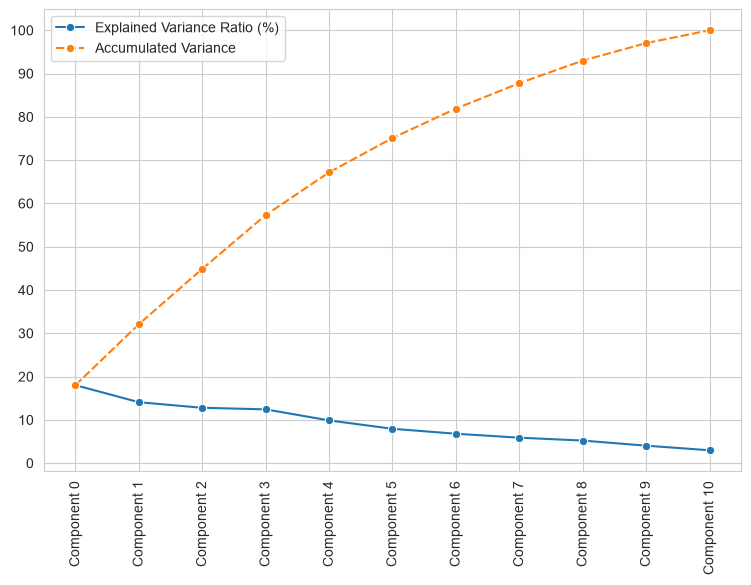

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

n_components = 11


def pca_components_analysis(df_pca, n_components):
    pca = PCA(n_components=n_components).fit(df_pca)
    x_PCA = pca.transform(df_pca)  # array with transformed PCA

    ComponentsList = ["Component " + str(number)
                      for number in range(n_components)]
    dfExplVarRatio = pd.DataFrame(
        data=np.round(100 * pca.explained_variance_ratio_, 3),
        index=ComponentsList,
        columns=['Explained Variance Ratio (%)'])

    dfExplVarRatio['Accumulated Variance'] = dfExplVarRatio['Explained Variance Ratio (%)'].cumsum(
    )

    PercentageOfDataExplained = dfExplVarRatio['Explained Variance Ratio (%)'].sum(
    )

    print(
        f"* The {n_components} components explain {round(PercentageOfDataExplained,2)}% of the data \n")
    plt.figure(figsize=(9, 6))
    sns.lineplot(data=dfExplVarRatio,  marker="o")
    plt.xticks(rotation=90)
    plt.yticks(np.arange(0, 110, 10))
    plt.show()


pca_components_analysis(df_pca=df_pca, n_components=n_components)


In [10]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

def PipelineCluster(n_components=7, n_clusters=3):

    pipeline_base = Pipeline([
        ("scaler", StandardScaler()),

        ("PCA", PCA(
            n_components=n_components,
            random_state=0
        )),

        ("model", KMeans(
            n_clusters=n_clusters,
            random_state=0,
            n_init=10
        ))
    ])

    return pipeline_base


* The 9 components explain 92.99% of the data 



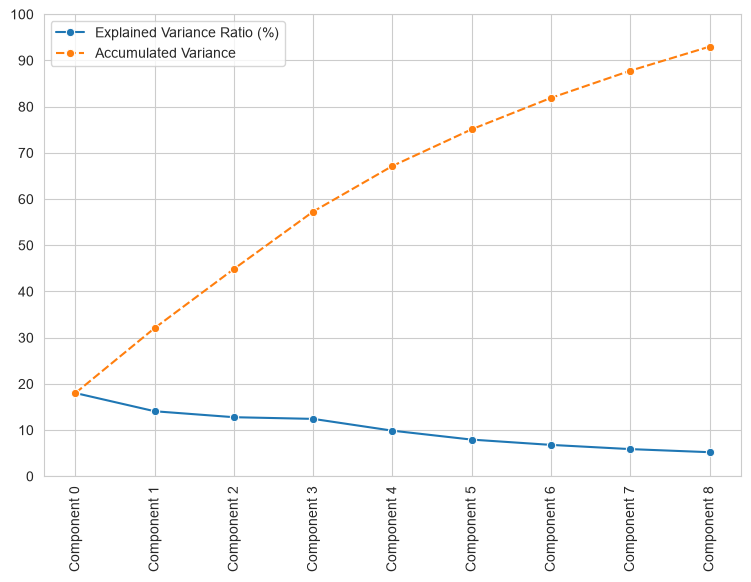

In [11]:
pca_components_analysis(df_pca=df_pca,n_components=9)

In [12]:
X_cluster = df.drop(
    columns=["DEATH_EVENT", "time"],
    errors="ignore"
)

print(X_cluster.shape)
print(X_cluster.columns.tolist())

(60, 11)
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']


In [13]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans


def PipelineCluster(n_clusters=6):

    pipeline_base = Pipeline([
        ("scaler", StandardScaler()),

        ("PCA", PCA(
            n_components=6,
            random_state=0
        )),

        ("model", KMeans(
            n_clusters=n_clusters,
            random_state=0,
            n_init=10
        ))
    ])

    return pipeline_base



PipelineCluster()


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('PCA', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",6
,"random_state random_state: int, RandomState instance or None, default=NoneUsed when the 'arpack' or 'randomized' solvers are used. Pass an intfor reproducible results across multiple function calls.See :term:`Glossary <random_state>`... versionadded:: 0.18.0",0
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise

In [14]:
X_cluster = df.drop(
    columns=["DEATH_EVENT", "time"],
    errors="ignore"
)

print("Clustering dataset shape:", X_cluster.shape)

Clustering dataset shape: (60, 11)


## Elbow Method and Silhouette Score

In [15]:
%pip install yellowbrick

Note: you may need to restart the kernel to use updated packages.


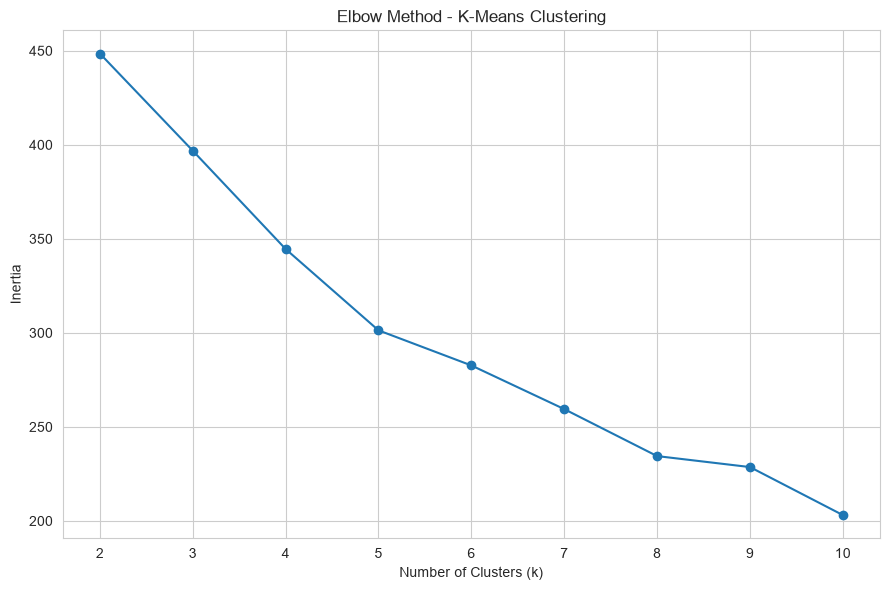

In [16]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Prepare data
X_cluster = df.drop(
    columns=["DEATH_EVENT", "time"],
    errors="ignore"
)

# Scale and apply PCA
preprocessing = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=7, random_state=0))
])

X_transformed = preprocessing.fit_transform(X_cluster)

# Calculate K-Means inertia for different cluster counts
inertia_values = []

cluster_range = range(2, 11)

for k in cluster_range:
    model = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=10
    )

    model.fit(X_transformed)
    inertia_values.append(model.inertia_)

# Plot Elbow Method
plt.figure(figsize=(9, 6))

plt.plot(
    list(cluster_range),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method - K-Means Clustering")
plt.xticks(list(cluster_range))
plt.grid(True)
plt.tight_layout()
plt.show()


In [17]:
def PipelineCluster():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("PCA", PCA(n_components=6, random_state=0)),
        ("model", KMeans(
            n_clusters=3,
            random_state=0,
            n_init=10
        ))
    ])

In [18]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

def PipelineCluster():
    pipeline_base = Pipeline([
        ("scaler", StandardScaler()),

        ("PCA", PCA(
            n_components=6,
            random_state=0
        )),

        ("model", KMeans(
            n_clusters=6,
            random_state=0,
            n_init=10
        ))
    ])

    return pipeline_base

# Initialize pipeline
pipeline_cluster = PipelineCluster()

print(pipeline_cluster)



Pipeline(steps=[('scaler', StandardScaler()),
                ('PCA', PCA(n_components=6, random_state=0)),
                ('model', KMeans(n_clusters=6, n_init=10, random_state=0))])


In [19]:
X_cluster = df.drop(
    columns=["DEATH_EVENT", "time"],
    errors="ignore"
)

pipeline_cluster = PipelineCluster()

cluster_labels = pipeline_cluster.fit_predict(X_cluster)

print("Cluster labels:", np.unique(cluster_labels))
print("Cluster sizes:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Cluster labels: [0 1 2 3 4 5]
Cluster sizes:
0     5
1    10
2    17
3     2
4    16
5    10
Name: count, dtype: int64


In [20]:
import pandas as pd

cluster_counts = pd.Series(
    pipeline_cluster["model"].labels_,
    name="Cluster"
).value_counts().sort_index()

print(cluster_counts)

Cluster
0     5
1    10
2    17
3     2
4    16
5    10
Name: count, dtype: int64


In [21]:
from sklearn.utils.validation import check_is_fitted

check_is_fitted(pipeline_cluster["model"])

print("K-Means pipeline is fitted.")

K-Means pipeline is fitted.


* The 6 components explain 75.11% of the data 



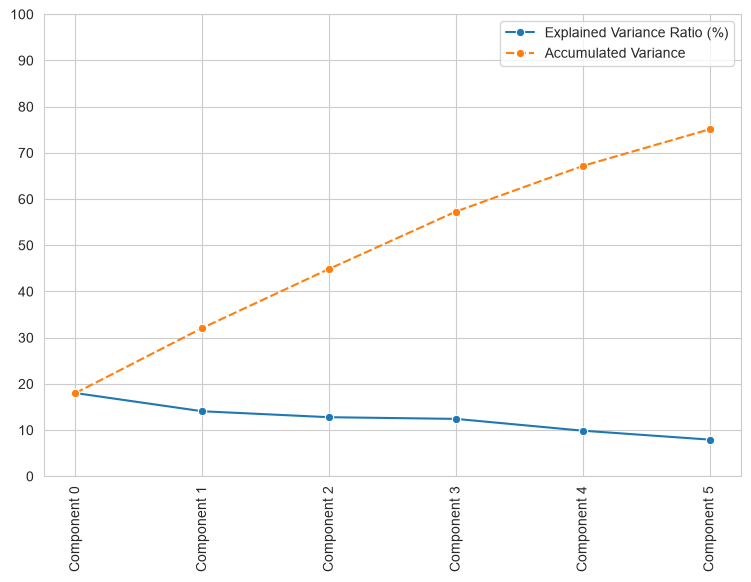

In [22]:
df_analysis=pca_components_analysis(df_pca=df_pca, n_components=6)

In [23]:
df_analysis = pipeline_cluster[:-1].transform(X_cluster)

print("PCA data:", df_analysis.shape)

PCA data: (60, 6)


In [24]:
# Transform the clustering dataset using the fitted
# StandardScaler and PCA steps

df_analysis = pipeline_cluster[:-1].transform(X_cluster)

print("PCA data shape:", df_analysis.shape)

PCA data shape: (60, 6)


In [25]:
pipeline_cluster = PipelineCluster()

cluster_labels = pipeline_cluster.fit_predict(X_cluster)

print("Number of clusters:", pipeline_cluster["model"].n_clusters)
print("Number of patients:", len(cluster_labels))

Number of clusters: 6
Number of patients: 60


In [26]:
df_analysis = pipeline_cluster[:-1].transform(X_cluster)

print("PCA data shape:", df_analysis.shape)

PCA data shape: (60, 6)


In [27]:
from sklearn.utils.validation import check_is_fitted

check_is_fitted(pipeline_cluster["model"])

print("K-Means pipeline is fitted.")

K-Means pipeline is fitted.


In [28]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

SAVE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "ml_pipeline"
    / "cluster_analysis"
    / "v1"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    pipeline_cluster,
    SAVE_DIR / "cluster_pipeline.pkl"
)

print("Clustering pipeline saved successfully!")

Clustering pipeline saved successfully!


In [29]:
print("Original dataset:", df.shape)
print("Clustering dataset:", X_cluster.shape)
print("PCA data:", df_analysis.shape)
print("Cluster labels:", len(pipeline_cluster["model"].labels_))

Original dataset: (60, 11)
Clustering dataset: (60, 11)
PCA data: (60, 6)
Cluster labels: 60


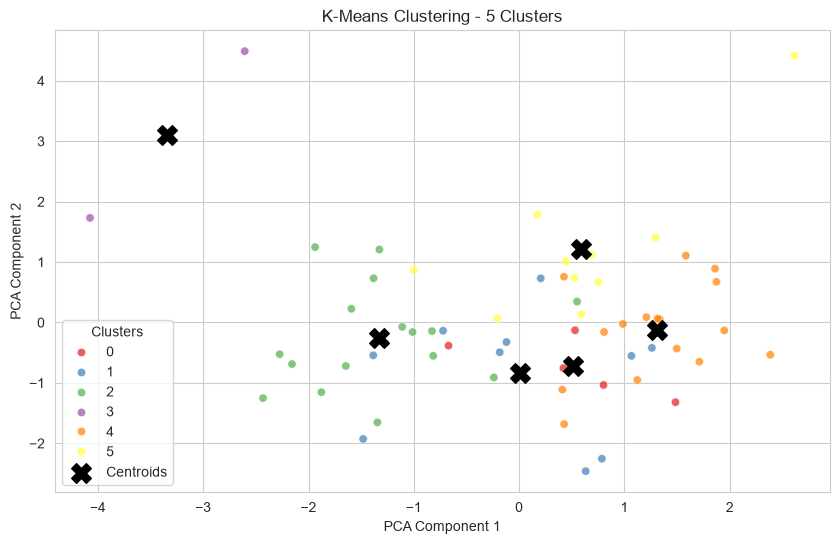

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# PCA coordinates used by the fitted KMeans model
df_analysis = pipeline_cluster[:-1].transform(X_cluster)

# Cluster centers
centroids = pipeline_cluster["model"].cluster_centers_

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=df_analysis[:, 0],
    y=df_analysis[:, 1],
    hue=cluster_labels,
    palette="Set1",
    alpha=0.7
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    color="black",
    label="Centroids"
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("K-Means Clustering - 5 Clusters")
plt.legend(title="Clusters")
plt.show()

Text(0.5, 1.0, 'K-Means Clustering - 6 Clusters')

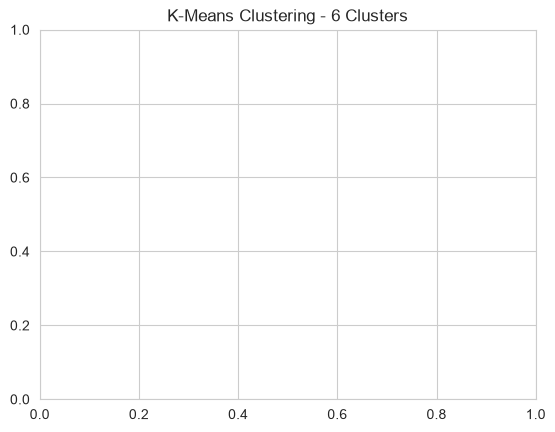

In [31]:
n_clusters = pipeline_cluster["model"].n_clusters

plt.title(f"K-Means Clustering - {n_clusters} Clusters")

In [32]:
print("PCA shape:", df_analysis.shape)
print("Cluster labels:", len(pipeline_cluster["model"].labels_))
print("Number of clusters:", pipeline_cluster["model"].n_clusters)

PCA shape: (60, 6)
Cluster labels: 60
Number of clusters: 6


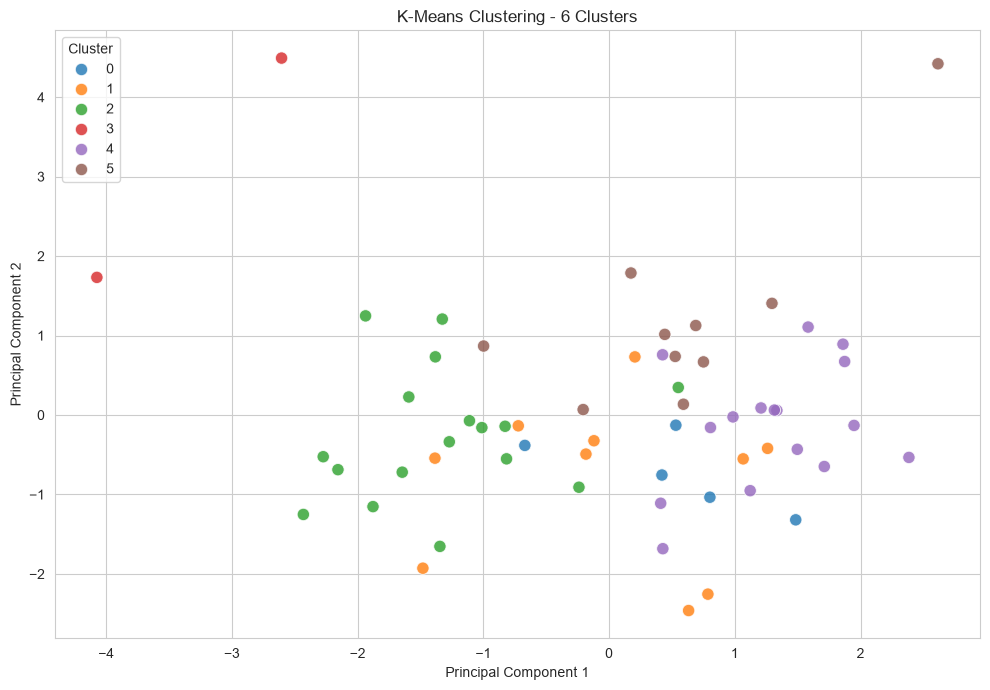

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# PCA-transformed data
X_pca = np.asarray(df_analysis)

# Cluster labels from fitted K-Means
cluster_labels = pipeline_cluster["model"].labels_

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette="tab10",
    s=80,
    alpha=0.8,
    ax=ax
)

ax.set_title(
    f"K-Means Clustering - {pipeline_cluster['model'].n_clusters} Clusters"
)
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")

ax.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [34]:
assert X_pca.shape[0] == len(cluster_labels)
assert X_pca.shape[1] >= 2

print("Data dimensions are valid.")

Data dimensions are valid.


In [35]:
from sklearn.metrics import silhouette_score

score = silhouette_score(df_analysis, cluster_labels)

print(f"Final Silhouette Score: {score:.4f}")

Final Silhouette Score: 0.2032


In [36]:
df_clustered = X_cluster.copy()
df_clustered["Cluster"] = cluster_labels

cluster_summary = df_clustered.groupby("Cluster").mean()

display(cluster_summary)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
Cluster,,,,,,,,,,,
0,63.800000,0.400000,186.000000,0.800000,34.600000,1.000000,244000.000000,1.060000,140.200000,1.000000,0.800
1,76.200000,0.400000,276.000000,0.000000,35.000000,0.300000,209535.803000,2.233000,133.000000,0.600000,0.100
2,55.039235,0.470588,270.705882,0.764706,46.352941,0.235294,272122.005294,1.041765,136.941176,0.117647,0.000
3,57.000000,0.500000,2195.500000,0.500000,66.000000,0.500000,207179.015000,7.900000,141.500000,0.000000,0.000
4,61.812500,0.187500,680.500000,0.437500,39.625000,0.000000,276504.630625,1.272500,135.625000,1.000000,0.875
5,51.200000,0.500000,1395.100000,0.100000,28.500000,0.400000,188400.000000,1.330000,139.500000,1.000000,0.100


=== Average Silhouette Score ===


2 clusters: 0.1910


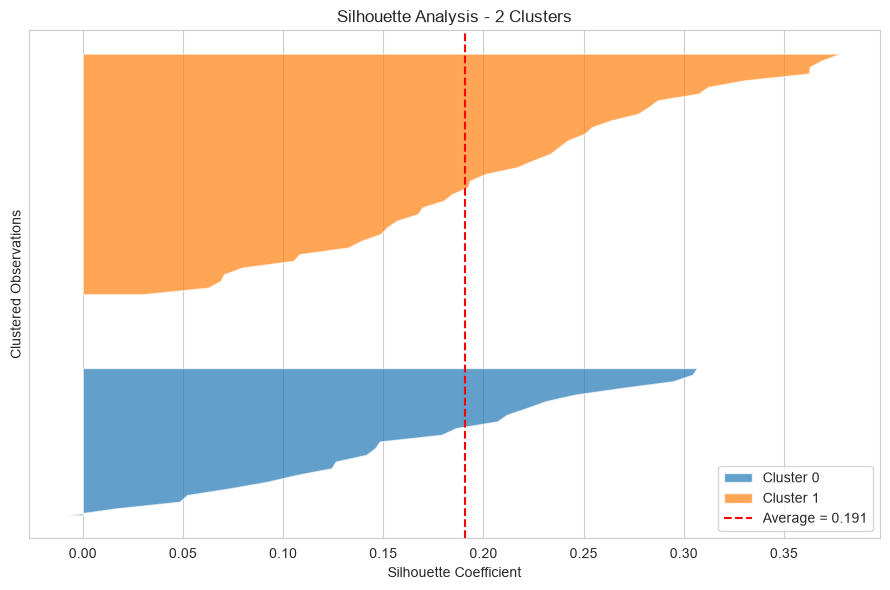

3 clusters: 0.1683


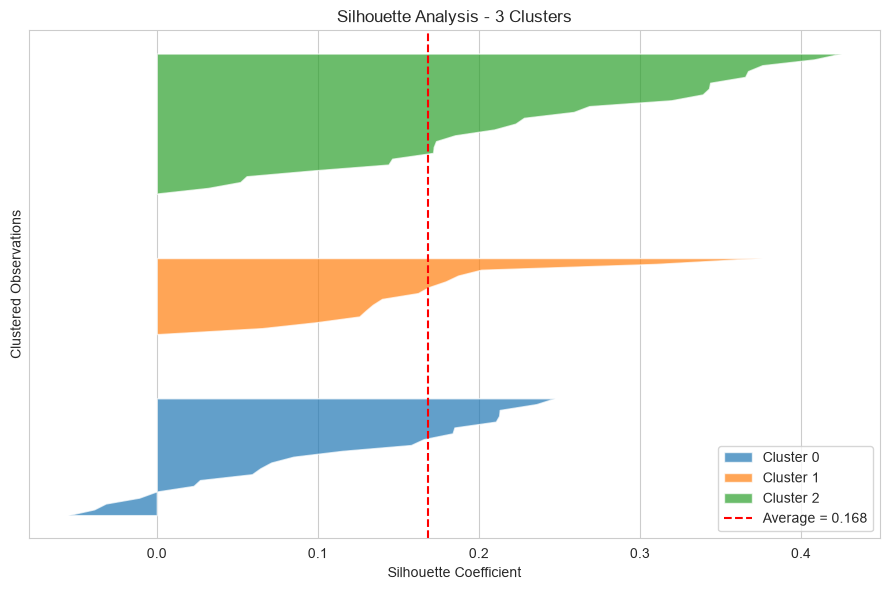

4 clusters: 0.1874


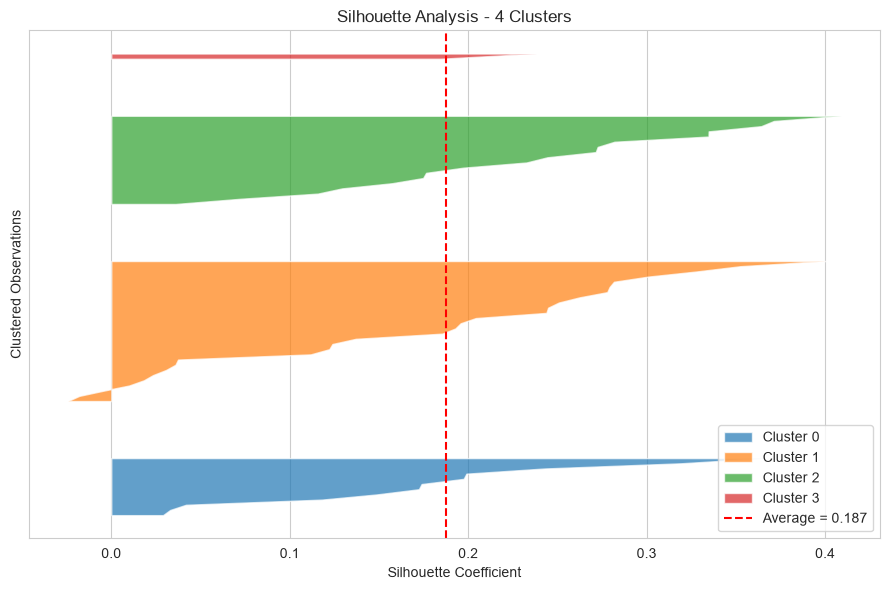

5 clusters: 0.1940


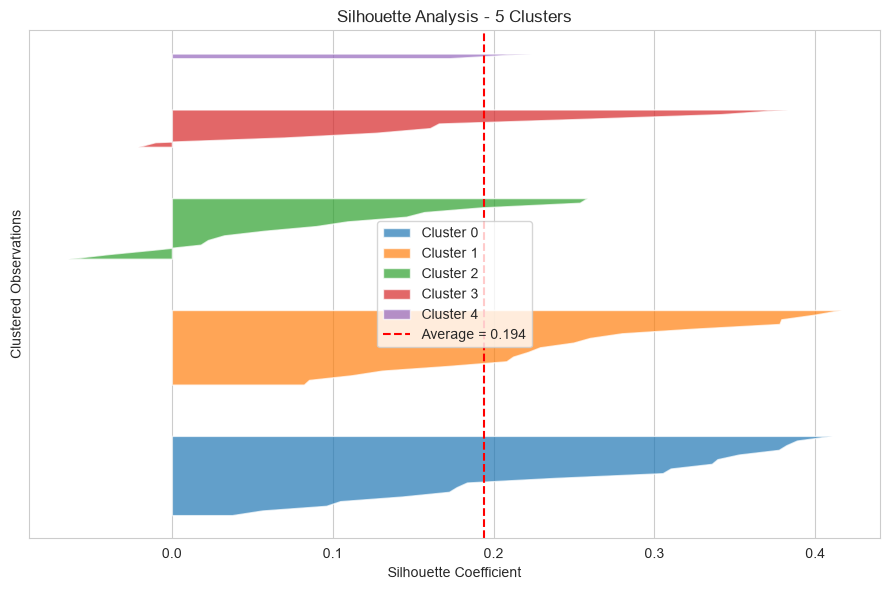

,Clusters,Silhouette Score
0,2,0.191013
1,3,0.168314
2,4,0.187432
3,5,0.193951


In [37]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Use your existing PCA-transformed data
X = np.asarray(df_analysis)

n_cluster_start = 2
n_cluster_stop = 6

results = []

print("=== Average Silhouette Score ===")

for n_clusters in range(n_cluster_start, n_cluster_stop):

    model = KMeans(
        n_clusters=n_clusters,
        random_state=0,
        n_init=10
    )

    cluster_labels = model.fit_predict(X)

    # Average silhouette score
    avg_score = silhouette_score(X, cluster_labels)

    results.append({
        "Clusters": n_clusters,
        "Silhouette Score": avg_score
    })

    print(f"{n_clusters} clusters: {avg_score:.4f}")

    # Silhouette values for individual observations
    sample_scores = silhouette_samples(X, cluster_labels)

    fig, ax = plt.subplots(figsize=(9, 6))

    y_lower = 10

    for i in range(n_clusters):

        cluster_scores = sample_scores[
            cluster_labels == i
        ]

        cluster_scores.sort()

        cluster_size = len(cluster_scores)
        y_upper = y_lower + cluster_size

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_scores,
            alpha=0.7,
            label=f"Cluster {i}"
        )

        y_lower = y_upper + 10

    # Average silhouette score reference
    ax.axvline(
        x=avg_score,
        color="red",
        linestyle="--",
        label=f"Average = {avg_score:.3f}"
    )

    ax.set_title(
        f"Silhouette Analysis - {n_clusters} Clusters"
    )
    ax.set_xlabel("Silhouette Coefficient")
    ax.set_ylabel("Clustered Observations")
    ax.set_yticks([])
    ax.legend()

    plt.tight_layout()
    plt.show()

# Display summary
results_df = pd.DataFrame(results)

display(results_df)


In [38]:
display(results_df)

,Clusters,Silhouette Score
0,2,0.191013
1,3,0.168314
2,4,0.187432
3,5,0.193951


In [39]:
best_k = int(
    results_df.loc[
        results_df["Silhouette Score"].idxmax(),
        "Clusters"
    ]
)

print("Best number of clusters:", best_k)

Best number of clusters: 5


## Fit Cluster Pipeline

Quick recap of our data for training cluster pipeline

In [40]:
X = df.copy()
print(X.shape)
X.head(3)

(60, 11)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,40.000,1,101,0,40,0,226000.0,0.8,141,0,0
1,60.667,1,151,1,40,1,201000.0,1.0,136,0,0
2,45.000,1,981,0,30,0,136000.0,1.1,137,1,0


Fit Cluster pipeline

In [41]:
pipeline_cluster = PipelineCluster()
pipeline_cluster.fit(X)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('PCA', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','anaemia','creatinine_phosphokinase',...,'serum_sodium','sex', 'smoking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Add cluster predictions to dataset

We add a column "`Clusters`" (with the cluster pipeline predictions) to the dataset

In [42]:
X['Clusters'] = pipeline_cluster['model'].labels_
print(X.shape)
X.head(3)

(60, 12)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,Clusters
0,40.000,1,101,0,40,0,226000.0,0.8,141,0,0,2
1,60.667,1,151,1,40,1,201000.0,1.0,136,0,0,2
2,45.000,1,981,0,30,0,136000.0,1.1,137,1,0,5


* Clusters frequencies 
          proportion
Clusters            
2               0.28
4               0.27
5               0.17
1               0.17
0               0.08
3               0.03 




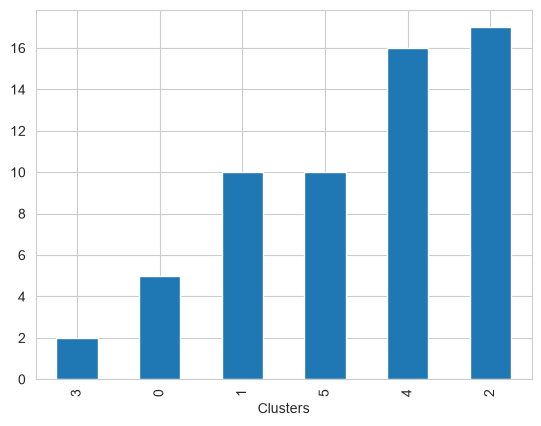

In [43]:
print(f"* Clusters frequencies \n{ X['Clusters'].value_counts(normalize=True).to_frame().round(2)} \n\n")
X['Clusters'].value_counts().sort_values().plot(kind='bar')
plt.show()

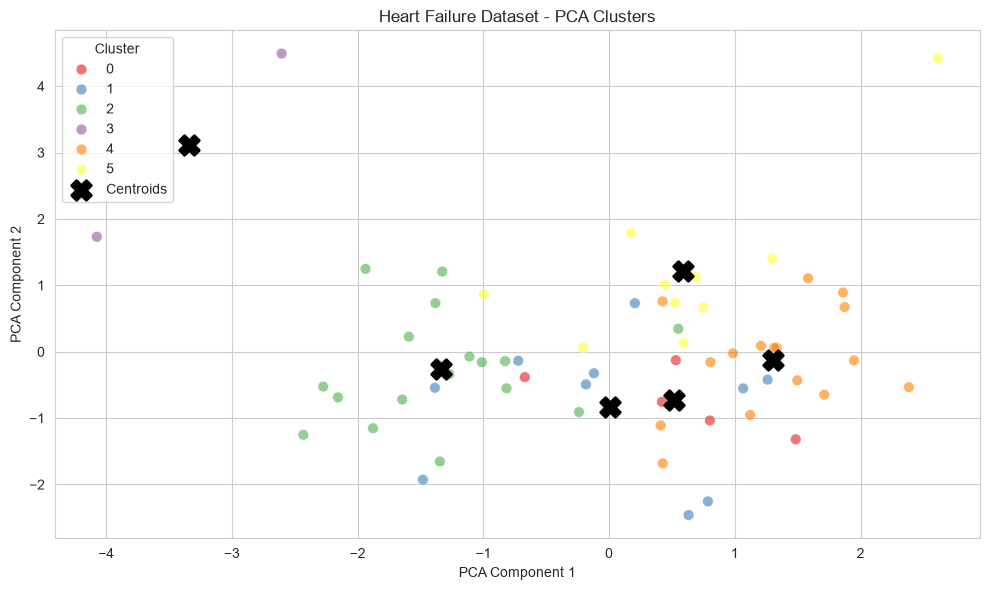

In [44]:

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Get PCA-transformed data from fitted pipeline
df_analysis = pipeline_cluster[:-1].transform(X_cluster)

# Retrieve cluster labels
cluster_labels = pipeline_cluster["model"].labels_

# Retrieve cluster centroids in PCA space
centroids = pipeline_cluster["model"].cluster_centers_

# Configure plot
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))

# Plot observations
sns.scatterplot(
    x=df_analysis[:, 0],
    y=df_analysis[:, 1],
    hue=cluster_labels,
    palette="Set1",
    alpha=0.6,
    s=60
)

# Plot cluster centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    linewidths=2,
    color="black",
    label="Centroids"
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Heart Failure Dataset - PCA Clusters")

plt.legend(title="Cluster")
plt.tight_layout()
plt.show()



We save the cluster predictions from this pipeline to use in the future. We will get back to that in a later stage.

In [45]:
print("PCA data shape:", df_analysis.shape)
print("Centroids shape:", centroids.shape)
print("Number of clusters:", len(np.unique(cluster_labels)))

PCA data shape: (60, 6)
Centroids shape: (6, 6)
Number of clusters: 6


In [46]:
cluster_predictions_with_all_variables = X['Clusters']
cluster_predictions_with_all_variables

0     2
1     2
2     5
3     2
4     1
5     2
6     1
7     2
8     3
9     4
10    2
11    1
12    4
13    5
14    0
15    4
16    2
17    4
18    5
19    0
20    4
21    5
22    1
23    5
24    1
25    2
26    5
27    2
28    0
29    2
30    2
31    2
32    2
33    2
34    3
35    1
36    4
37    4
38    4
39    1
40    2
41    5
42    4
43    0
44    1
45    5
46    4
47    2
48    4
49    4
50    4
51    5
52    5
53    4
54    0
55    1
56    2
57    1
58    4
59    4
Name: Clusters, dtype: int32

## Fit a classifier, where the target is cluster predictions and features remaining variables

We copy `X` to a DataFrame `df_clf`

In [47]:
df_clf = X.copy()
print(df_clf.shape)
df_clf.head(3)

(60, 12)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,Clusters
0,40.000,1,101,0,40,0,226000.0,0.8,141,0,0,2
1,60.667,1,151,1,40,1,201000.0,1.0,136,0,0,2
2,45.000,1,981,0,30,0,136000.0,1.1,137,1,0,5


Split Train and Test sets

In [48]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    df_clf.drop(['Clusters'], axis=1),
    df_clf['Clusters'],
    test_size=0.2,
    random_state=0
)

print(X_train.shape, X_test.shape)


(48, 11) (12, 11)


Create classifier pipeline steps

In [49]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

def PipelineClf2ExplainClusters():
    return Pipeline([
        ("model", GradientBoostingClassifier(random_state=0))
    ])

Fit the classifier to the training data

In [50]:
PipelineClf2ExplainClusters()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required 

In [51]:
from sklearn.model_selection import train_test_split

# Original clinical features
X = X_cluster.copy()

# Target: cluster labels assigned by K-Means
y = pipeline_cluster["model"].labels_

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

In [52]:
pipeline_clf_cluster = PipelineClf2ExplainClusters()

pipeline_clf_cluster.fit(X_train, y_train)

print("Classifier fitted successfully!")

Classifier fitted successfully!


In [53]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = pipeline_clf_cluster.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Accuracy: 0.5833333333333334
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.00      0.00      0.00         2
           2       0.75      0.75      0.75         4
           4       0.50      1.00      0.67         3
           5       1.00      0.50      0.67         2

    accuracy                           0.58        12
   macro avg       0.45      0.45      0.42        12
weighted avg       0.54      0.58      0.53        12



In [54]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": pipeline_clf_cluster["model"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
7,serum_creatinine,0.147623
9,sex,0.136718
10,smoking,0.132559
8,serum_sodium,0.116739
2,creatinine_phosphokinase,0.104572
0,age,0.100437
6,platelets,0.070882
5,high_blood_pressure,0.068422
4,ejection_fraction,0.068308
3,diabetes,0.049436


In [55]:
pipeline_clf_cluster = PipelineClf2ExplainClusters()
pipeline_clf_cluster.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](6,)","[0,1,2,3,4,5]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','anaemia','creatinine_phosphokinase',...,'serum_sodium','sex', 'smoking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1


In [56]:
print(PipelineClf2ExplainClusters())

Pipeline(steps=[('model', GradientBoostingClassifier(random_state=0))])


In [57]:
# Generate cluster labels for training data
y_cluster_train = pipeline_cluster.predict(X_train)

# Initialize classifier
pipeline_clf_cluster = PipelineClf2ExplainClusters()

# Fit classifier to predict cluster membership
pipeline_clf_cluster.fit(X_train, y_cluster_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](6,)","[0,1,2,3,4,5]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','anaemia','creatinine_phosphokinase',...,'serum_sodium','sex', 'smoking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1


In [58]:
pipeline_clf_cluster = PipelineClf2ExplainClusters()
pipeline_clf_cluster.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](6,)","[0,1,2,3,4,5]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','anaemia','creatinine_phosphokinase',...,'serum_sodium','sex', 'smoking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1


## Evaluate classifier performance on Train and Test Sets

In [59]:
from sklearn.metrics import classification_report
print(classification_report(y_train, pipeline_clf_cluster.predict(X_train)))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00        13
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00        13
           5       1.00      1.00      1.00         8

    accuracy                           1.00        48
   macro avg       1.00      1.00      1.00        48
weighted avg       1.00      1.00      1.00        48



In [60]:
print(classification_report(y_test, pipeline_clf_cluster.predict(X_test)))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         1
           1       0.00      0.00      0.00         2
           2       0.75      0.75      0.75         4
           4       0.50      1.00      0.67         3
           5       1.00      0.50      0.67         2

    accuracy                           0.58        12
   macro avg       0.45      0.45      0.42        12
weighted avg       0.54      0.58      0.53        12



c:\python_projects\Predictive_analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\python_projects\Predictive_analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\python_projects\Predictive_analysis\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

## Assess the most important Features that define a cluster

Pipeline steps: dict_keys(['model'])
These are the 11 features in descending order of importance:
['serum_creatinine', 'sex', 'smoking', 'serum_sodium', 'creatinine_phosphokinase', 'age', 'platelets', 'high_blood_pressure', 'ejection_fraction', 'diabetes', 'anaemia']


,Feature,Importance
7,serum_creatinine,0.147623
9,sex,0.136718
10,smoking,0.132559
8,serum_sodium,0.116739
2,creatinine_phosphokinase,0.104572
0,age,0.100437
6,platelets,0.070882
5,high_blood_pressure,0.068422
4,ejection_fraction,0.068308
3,diabetes,0.049436


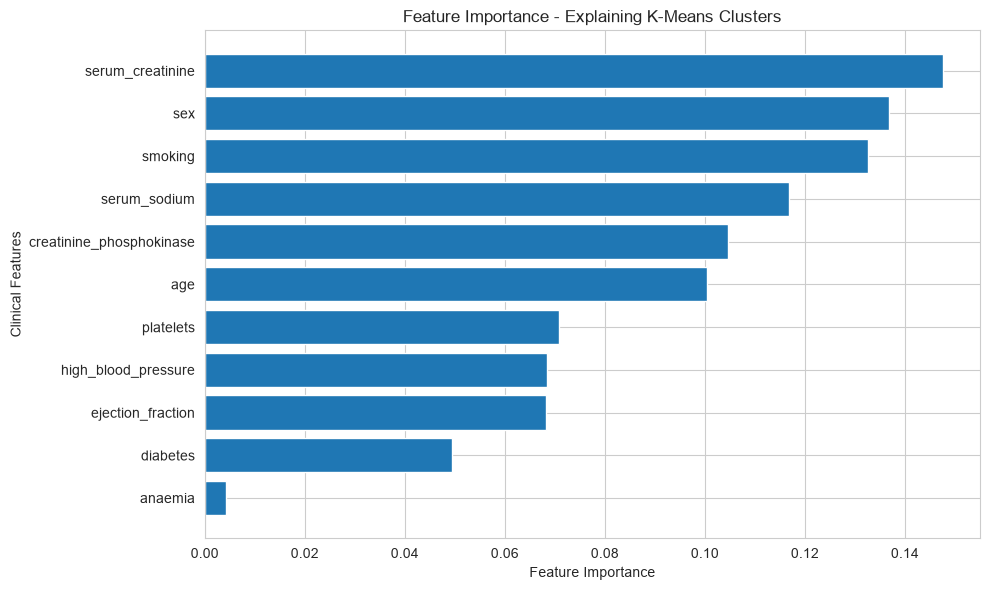

In [61]:

import pandas as pd
import matplotlib.pyplot as plt

# Check pipeline steps
print("Pipeline steps:", pipeline_clf_cluster.named_steps.keys())

# Extract feature names
feature_names = pipeline_clf_cluster.feature_names_in_

# Extract feature importance from Gradient Boosting
feature_importance = pipeline_clf_cluster["model"].feature_importances_

# Create DataFrame
df_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
}).sort_values(
    by="Importance",
    ascending=False
)

# Most important features
best_features = df_feature_importance["Feature"].tolist()

print(
    f"These are the {len(best_features)} features "
    f"in descending order of importance:\n{best_features}"
)

display(df_feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    df_feature_importance["Feature"][::-1],
    df_feature_importance["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Clinical Features")
plt.title("Feature Importance - Explaining K-Means Clusters")
plt.tight_layout()
plt.show()


We will store the best_features to use at a later stage.

In [62]:
best_features_pipeline_all_variables = best_features
best_features_pipeline_all_variables

['serum_creatinine',
 'sex',
 'smoking',
 'serum_sodium',
 'creatinine_phosphokinase',
 'age',
 'platelets',
 'high_blood_pressure',
 'ejection_fraction',
 'diabetes',
 'anaemia']

## Cluster Analysis

Load function that plots a table with description for all Clusters

In [63]:

def DescriptionAllClusters(df, decimal_points=3):

    DescriptionAllClusters = pd.DataFrame(
        columns=df.drop(['Clusters'], axis=1).columns)
    # iterate on each cluster , calls Clusters_IndividualDescription()
    for cluster in df.sort_values(by='Clusters')['Clusters'].unique():

        EDA_ClusterSubset = df.query(
            f"Clusters == {cluster}").drop(['Clusters'], axis=1)
        ClusterDescription = Clusters_IndividualDescription(
            EDA_ClusterSubset, cluster, decimal_points)
        DescriptionAllClusters = pd.concat(
            [ClusterDescription, DescriptionAllClusters])

    DescriptionAllClusters.set_index(['Cluster'], inplace=True)
    return DescriptionAllClusters


def Clusters_IndividualDescription(EDA_Cluster, cluster, decimal_points):

    ClustersDescription = pd.DataFrame(columns=EDA_Cluster.columns)
    # for a given cluster, iterate over all columns
    # if the variable is numerical, calculate the IQR: display as Q1 -- Q3.
    # That will show the range for the most common values for the numerical variable
    # if the variable is categorical, count the frequencies and displays the top 3 most frequent
    # That will show the most common levels for the category

    for col in EDA_Cluster.columns:

        try:  # eventually a given cluster will have only missing data for a given variable

            if EDA_Cluster[col].dtypes == 'object':

                top_frequencies = EDA_Cluster.dropna(
                    subset=[col])[[col]].value_counts(normalize=True).nlargest(n=3)
                Description = ''

                for x in range(len(top_frequencies)):
                    freq = top_frequencies.iloc[x]
                    category = top_frequencies.index[x][0]
                    CategoryPercentage = int(round(freq*100, 0))
                    statement = f"'{category}': {CategoryPercentage}% , "
                    Description = Description + statement

                ClustersDescription.at[0, col] = Description[:-2]

            elif EDA_Cluster[col].dtypes in ['float', 'int']:
                DescStats = EDA_Cluster.dropna(subset=[col])[[col]].describe()
                Q1 = round(DescStats.iloc[4, 0], decimal_points)
                Q3 = round(DescStats.iloc[6, 0], decimal_points)
                Description = f"{Q1} -- {Q3}"
                ClustersDescription.at[0, col] = Description

        except Exception as e:
            ClustersDescription.at[0, col] = 'Not available'
            print(
                f"** Error Exception: {e} - cluster {cluster}, variable {col}")

    ClustersDescription['Cluster'] = str(cluster)

    return ClustersDescription


Load a custom function to plot cluster distribution per Variable (absolute and relative levels)

In [64]:
!pip install plotly


In [65]:
import plotly.express as px


def cluster_distribution_per_variable(df, target):
    """
    The data should have 2 variables, the cluster predictions and
    the variable you want to analyze with, in this case we call "target".
    We use plotly express to create 2 plots:
    Cluster distribution across the target.
    Relative presence of the target level in each cluster.
    """
    df_bar_plot = df.groupby(['Clusters', target]).size().reset_index(name='Count')
    df_bar_plot.columns = ['Clusters', target, 'Count']
    df_bar_plot[target] = df_bar_plot[target].astype('object')

    print(f"Clusters distribution across {target} levels")
    fig = px.bar(df_bar_plot, x='Clusters', y='Count',
                 color=target, width=800, height=500)
    fig.update_layout(xaxis=dict(tickmode='array',
                      tickvals=df['Clusters'].unique()))
    fig.show(renderer='jupyterlab')

    df_relative = (df
                   .groupby(["Clusters", target])
                   .size()
                   .unstack(fill_value=0)
                   .apply(lambda x: 100 * x / x.sum(), axis=1)
                   .stack()
                   .reset_index(name='Relative Percentage (%)')
                   .sort_values(by=['Clusters', target])
                   )

    print(f"Relative Percentage (%) of {target} in each cluster")
    fig = px.line(df_relative, x='Clusters', y='Relative Percentage (%)',
                  color=target, width=800, height=500)
    fig.update_layout(xaxis=dict(tickmode='array',
                      tickvals=df['Clusters'].unique()))
    fig.update_traces(mode='markers+lines')
    fig.show(renderer='jupyterlab')



Create a DataFrame that contains best features and Clusters Predictions since we want to analyse the patterns for each cluster.


In [66]:
df_cluster_profile = df_clf.copy()
df_cluster_profile = df_cluster_profile.filter(items=best_features + ['Clusters'], axis=1)
print(df_cluster_profile.shape)
df_cluster_profile.head(3)

(60, 12)


,serum_creatinine,sex,smoking,serum_sodium,creatinine_phosphokinase,age,platelets,high_blood_pressure,ejection_fraction,diabetes,anaemia,Clusters
0,0.8,0,0,141,101,40.000,226000.0,0,40,0,1,2
1,1.0,0,0,136,151,60.667,201000.0,1,40,1,1,2
2,1.1,1,0,137,981,45.000,136000.0,0,30,0,1,5


We want also to analyse death_event levels.

### Cluster profile based on the best features

In [67]:
print(df.columns.tolist())
print(df.shape)

['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
(60, 11)


In [68]:
X_cluster = df.drop(
    columns=["time", "DEATH_EVENT"],
    errors="ignore"
).copy()

In [69]:
# Fit clustering model
pipeline_cluster = PipelineCluster()
cluster_labels = pipeline_cluster.fit_predict(X_cluster)

# Select important features
df_cluster_profile = X_cluster[best_features].copy()

# Add cluster labels
df_cluster_profile["Clusters"] = cluster_labels

# Check result
print(df_cluster_profile.shape)
display(df_cluster_profile.head())

(60, 12)


,serum_creatinine,sex,smoking,serum_sodium,creatinine_phosphokinase,age,platelets,high_blood_pressure,ejection_fraction,diabetes,anaemia,Clusters
0,0.8,0,0,141,101,40.000,226000.0,0,40,0,1,2
1,1.0,0,0,136,151,60.667,201000.0,1,40,1,1,2
2,1.1,1,0,137,981,45.000,136000.0,0,30,0,1,5
3,0.7,0,0,140,582,55.000,371000.0,1,35,1,0,2
4,1.2,1,0,132,232,70.000,173000.0,0,30,0,0,1


In [70]:
print("Available columns:", X_cluster.columns.tolist())
print("Best features:", best_features)

missing_features = [
    feature for feature in best_features
    if feature not in X_cluster.columns
]

print("Missing features:", missing_features)

Available columns: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
Best features: ['serum_creatinine', 'sex', 'smoking', 'serum_sodium', 'creatinine_phosphokinase', 'age', 'platelets', 'high_blood_pressure', 'ejection_fraction', 'diabetes', 'anaemia']
Missing features: []


In [71]:
best_features = [
    feature for feature in best_features
    if feature in X_cluster.columns
]

In [72]:
# Prepare clustering features
X_cluster = df.drop(
    columns=["time", "DEATH_EVENT"],
    errors="ignore"
).copy()

# Fit the existing pipeline
cluster_labels = pipeline_cluster.fit_predict(X_cluster)

print("Number of clusters:", len(set(cluster_labels)))
print("Number of patients:", len(cluster_labels))

Number of clusters: 6
Number of patients: 60


In [73]:
# Clinical features used to describe the clusters
df_cluster_profile = X_cluster[best_features].copy()

# Add cluster membership
df_cluster_profile["Cluster"] = pipeline_cluster.predict(X_cluster)

print(df_cluster_profile.shape)
display(df_cluster_profile.head())

(60, 12)


,serum_creatinine,sex,smoking,serum_sodium,creatinine_phosphokinase,age,platelets,high_blood_pressure,ejection_fraction,diabetes,anaemia,Cluster
0,0.8,0,0,141,101,40.000,226000.0,0,40,0,1,2
1,1.0,0,0,136,151,60.667,201000.0,1,40,1,1,2
2,1.1,1,0,137,981,45.000,136000.0,0,30,0,1,5
3,0.7,0,0,140,582,55.000,371000.0,1,35,1,0,2
4,1.2,1,0,132,232,70.000,173000.0,0,30,0,0,1


In [74]:
# Select important clinical features
df_cluster_profile = X_cluster[best_features].copy()

# Add cluster labels
df_cluster_profile["Clusters"] = pipeline_cluster.predict(X_cluster)

# Generate cluster profile
clusters_profile = DescriptionAllClusters(
    df=df_cluster_profile,
    decimal_points=0
)

display(clusters_profile)

,serum_creatinine,sex,smoking,serum_sodium,creatinine_phosphokinase,age,platelets,high_blood_pressure,ejection_fraction,diabetes,anaemia
Cluster,,,,,,,,,,,
5,1.0 -- 1.0,1.0 -- 1.0,0.0 -- 0.0,138.0 -- 140.0,282.0 -- 1900.0,46.0 -- 55.0,137250.0 -- 222250.0,0.0 -- 1.0,25.0 -- 34.0,0.0 -- 0.0,0.0 -- 1.0
4,1.0 -- 1.0,1.0 -- 1.0,1.0 -- 1.0,135.0 -- 137.0,292.0 -- 795.0,54.0 -- 68.0,259500.0 -- 306250.0,0.0 -- 0.0,35.0 -- 45.0,0.0 -- 1.0,0.0 -- 0.0
3,7.0 -- 8.0,0.0 -- 0.0,0.0 -- 0.0,139.0 -- 144.0,1311.0 -- 3080.0,56.0 -- 58.0,179090.0 -- 235269.0,0.0 -- 1.0,64.0 -- 68.0,0.0 -- 1.0,0.0 -- 1.0
2,1.0 -- 1.0,0.0 -- 0.0,0.0 -- 0.0,136.0 -- 139.0,101.0 -- 582.0,45.0 -- 65.0,222000.0 -- 271000.0,0.0 -- 0.0,38.0 -- 60.0,1.0 -- 1.0,0.0 -- 1.0
1,1.0 -- 2.0,0.0 -- 1.0,0.0 -- 0.0,132.0 -- 135.0,126.0 -- 377.0,66.0 -- 88.0,178750.0 -- 236500.0,0.0 -- 1.0,30.0 -- 40.0,0.0 -- 0.0,0.0 -- 1.0
0,1.0 -- 1.0,1.0 -- 1.0,1.0 -- 1.0,140.0 -- 142.0,94.0 -- 220.0,62.0 -- 68.0,188000.0 -- 289000.0,1.0 -- 1.0,30.0 -- 38.0,1.0 -- 1.0,0.0 -- 1.0


In [75]:
from pathlib import Path

SAVE_DIR = (
    Path(r"C:\python_projects\Predictive_analysis")
    / "outputs"
    / "ml_pipeline"
    / "cluster_analysis"
    / "v1"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

clusters_profile.to_csv(
    SAVE_DIR / "clusters_profile.csv",
    index=False
)

print("Cluster profile saved successfully!")

Cluster profile saved successfully!


In [76]:
import joblib

joblib.dump(
    pipeline_cluster,
    SAVE_DIR / "cluster_pipeline.pkl"
)

print("K-Means pipeline saved successfully!")

K-Means pipeline saved successfully!


In [77]:
pd.set_option('display.max_colwidth', None)

clusters_profile = DescriptionAllClusters(
    df=pd.concat([df_cluster_profile, df_reduced], axis=1),
    decimal_points=0
)

clusters_profile

NameError: name 'df_reduced' is not defined

In [ ]:
pd.set_option('display.max_colwidth', None)
clusters_profile = DescriptionAllClusters(df=pd.concat([df_cluster_profile,df_reduced], axis=1), decimal_points=0)
clusters_profile

NameError: name 'df_reduced' is not defined

In [ ]:
print("df_cluster_profile:", df_cluster_profile.columns.tolist())
print("df_reduced:", df_reduced.columns.tolist())

duplicate_columns = df_cluster_profile.columns.intersection(
    df_reduced.columns
)

print("Duplicate columns:", duplicate_columns.tolist())

df_cluster_profile: ['serum_creatinine', 'sex', 'smoking', 'serum_sodium', 'creatinine_phosphokinase', 'age', 'platelets', 'high_blood_pressure', 'ejection_fraction', 'diabetes', 'anaemia', 'Clusters']


NameError: name 'df_reduced' is not defined

In [ ]:
import joblib

joblib.dump(
    pipeline_cluster,
    SAVE_DIR / "cluster_pipeline.pkl"
)

print("K-Means pipeline saved successfully!")

K-Means pipeline saved successfully!


In [ ]:
import pandas as pd

pd.set_option("display.max_colwidth", None)

# Select only columns not already present
additional_columns = df_reduced.columns.difference(
    df_cluster_profile.columns
)

# Combine without duplicate columns
df_combined = pd.concat(
    [
        df_cluster_profile,
        df_reduced[additional_columns]
    ],
    axis=1
)

# Check for missing values caused by index misalignment
print("Shape:", df_combined.shape)
print("Missing values:", df_combined.isna().sum().sum())

# Generate cluster profile
clusters_profile = DescriptionAllClusters(
    df=df_combined,
    decimal_points=0
)

display(clusters_profile)

NameError: name 'df_reduced' is not defined

In [ ]:
import pandas as pd

pd.set_option("display.max_colwidth", None)

# Select only columns not already present
additional_columns = df_reduced.columns.difference(
    df_cluster_profile.columns
)

# Combine without duplicate columns
df_combined = pd.concat(
    [
        df_cluster_profile,
        df_reduced[additional_columns]
    ],
    axis=1
)

# Check for missing values caused by index misalignment
print("Shape:", df_combined.shape)
print("Missing values:", df_combined.isna().sum().sum())

# Generate cluster profile
clusters_profile = DescriptionAllClusters(
    df=df_combined,
    decimal_points=0
)

display(clusters_profile)

NameError: name 'df_reduced' is not defined

In [ ]:
model_path = SAVE_DIR / "cluster_pipeline.pkl"

print("File exists:", model_path.exists())
print("Model path:", model_path)

File exists: True
Model path: C:\python_projects\Predictive_analysis\outputs\ml_pipeline\cluster_analysis\v1\cluster_pipeline.pkl


### Clusters distribution across  & Relative Percentage in each cluster

In [ ]:
df_cluster_vs_df_reduced = pd.DataFrame(
    {
        "DEATH_EVENT": TrainSet.loc[X_cluster.index, "DEATH_EVENT"],
        "Clusters": pipeline_cluster.predict(X_cluster)
    },
    index=X_cluster.index
)

cluster_distribution_per_variable(
    df=df_cluster_vs_df_reduced,
    target="DEATH_EVENT"
)

NameError: name 'TrainSet' is not defined

# Fit New Cluster Pipeline with most important features

In order to reduce feature space, we will study the trade-off between the previous Cluster Pipeline (fitted with all variables) and Pipeline using the variables that are most important to define the clusters from the previous pipeline

In [ ]:
best_features_pipeline_all_variables

['sex',
 'smoking',
 'age',
 'serum_sodium',
 'high_blood_pressure',
 'creatinine_phosphokinase',
 'serum_creatinine',
 'ejection_fraction',
 'platelets',
 'diabetes',
 'anaemia']

## Define trade-off and metrics to compare new and previous Cluster Pipeline

To evaluate this trade-off we will
1. Conduct a elbow method and silhouette analysis and check if the same number of clusters is suggested
2. Fit new cluster pipeline and compare if the predictions from this pipeline are "equivalent" to the predictions from the previous pipeline
3. Fit a classifier to explain cluster, and check if performance on Train and Test sets is similar to the previous pipeline
4. Check if the most important features for the classifier are the same from the previous pipeline
5. Compare if the cluster profile from both pipelines are "equivalent"

If we are happy to say **yes** for them, we can use a cluster pipeline using the features that best define the clusters from previous pipeline!
* The **gain** is that in real-time (which is the major purpose of Machine Learning) you will need fewer variables for predicting clusters for your prospects.

## Subset data with the most relevant variables

In [ ]:
df_reduced = df.filter(best_features_pipeline_all_variables)
df_reduced.head(3)

,sex,smoking,age,serum_sodium,high_blood_pressure,creatinine_phosphokinase,serum_creatinine,ejection_fraction,platelets,diabetes,anaemia
0,0,0,40.000,141,0,101,0.8,40,226000.0,0,1
1,0,0,60.667,136,1,151,1.0,40,201000.0,1,1
2,1,0,45.000,137,0,981,1.1,30,136000.0,0,1


## Rewrite Cluster Pipeline

In [ ]:
def PipelineCluster():
    pipeline_base = Pipeline([

        # we update the pipeline, considering only the most important variables from the previous pipeline
        ("OrdinalCategoricalEncoder", OrdinalEncoder(encoding_method='arbitrary',
                                                     variables=['time', 'DEATH_EVENT'])),

        # it doesn't need SmartCorrelation

        ("scaler", StandardScaler()),

        # No PCA step needed, since we know which features to consider

        ("model", KMeans(n_clusters=3, random_state=0)),


    ])
    return pipeline_base


PipelineCluster()


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('OrdinalCategoricalEncoder', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,encoding_method,'arbitrary'
,variables,"['time', 'DEATH_EVENT']"
,missing_values,'raise'
,ignore_format,False
,unseen,'ignore'
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True


## Apply Elbow Method and Silhouette analysis

In [ ]:
import pandas as pd

df_reduced = pd.read_csv(r"C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\collection\HeartFailureData.csv"
).filter(["DEATH_EVENT"])

df_reduced["DEATH_EVENT"] = df_reduced["DEATH_EVENT"].astype("category")

df_reduced.head(3)

,DEATH_EVENT
0,1
1,1
2,1


In [ ]:
print("Available columns:", df_reduced.columns.tolist())

pipeline_cluster = PipelineCluster()

print("Pipeline steps:")
for name, step in pipeline_cluster.steps:
    print(name, ":", step)

Available columns: ['DEATH_EVENT']
Pipeline steps:
scaler : StandardScaler()
PCA : PCA(n_components=6, random_state=0)
model : KMeans(n_clusters=6, n_init=10, random_state=0)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

def PipelineCluster():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("PCA", PCA(n_components=6, random_state=0)),
        ("model", KMeans(
            n_clusters=6,
            random_state=0,
            n_init=10
        ))
    ])

In [ ]:
X_cluster = df.drop(
    columns=["time", "DEATH_EVENT"],
    errors="ignore"
).copy()

pipeline_cluster = PipelineCluster()

# Fit the complete clustering pipeline
cluster_labels = pipeline_cluster.fit_predict(X_cluster)

# Extract the PCA-transformed data
df_analysis = pipeline_cluster[:-1].transform(X_cluster)

print(df_analysis.shape)
print(type(df_analysis))

(60, 6)
<class 'numpy.ndarray'>


Elbow Analysis

## Fit New Cluster Pipeline

We set X as our training set for the cluster. It is a copy of df_reduced

In [ ]:
X = df_reduced.copy()
print(X.shape)
X.head(3)

(299, 1)


,DEATH_EVENT
0,1
1,1
2,1


Fit Cluster pipeline

In [ ]:
X_cluster = df.drop(
    columns=["time", "DEATH_EVENT"],
    errors="ignore"
).copy()

pipeline_cluster = PipelineCluster()

# Fit the complete clustering pipeline
cluster_labels = pipeline_cluster.fit_predict(X_cluster)

# Extract the PCA-transformed data
df_analysis = pipeline_cluster[:-1].transform(X_cluster)

print(df_analysis.shape)
print(type(df_analysis))

(60, 6)
<class 'numpy.ndarray'>


In [ ]:
pipeline_cluster = PipelineCluster()
pipeline_cluster.fit(X)

ValueError: n_components=6 must be between 0 and min(n_samples, n_features)=1 with svd_solver='covariance_eigh'

In [ ]:
import pandas as pd

# Use clinical predictors only
X_cluster = TrainSet.drop(
    columns=["DEATH_EVENT", "time", "Clusters"],
    errors="ignore"
)

print("Clustering input shape:", X_cluster.shape)

# Predict using fitted clustering pipeline
cluster_labels = pipeline_cluster.predict(X_cluster)

# Create results DataFrame
df_cluster_vs_df_reduced = pd.DataFrame(
    {
        "Clusters": cluster_labels,
        "DEATH_EVENT": TrainSet["DEATH_EVENT"].to_numpy()
    },
    index=TrainSet.index
)

display(df_cluster_vs_df_reduced.head())

cluster_distribution_per_variable(
    df=df_cluster_vs_df_reduced,
    target="DEATH_EVENT"
)

NameError: name 'TrainSet' is not defined

## Add cluster predictions to dataset

We add a column "`Clusters`" (with the cluster pipeline predictions) to the dataset

In [ ]:
X['Clusters'] = pipeline_cluster['model'].labels_
print(X.shape)
X.head(3)

AttributeError: 'KMeans' object has no attribute 'labels_'

* Clusters frequencies 
          proportion
Clusters            
2               0.28
4               0.27
5               0.17
1               0.17
0               0.08
3               0.03 




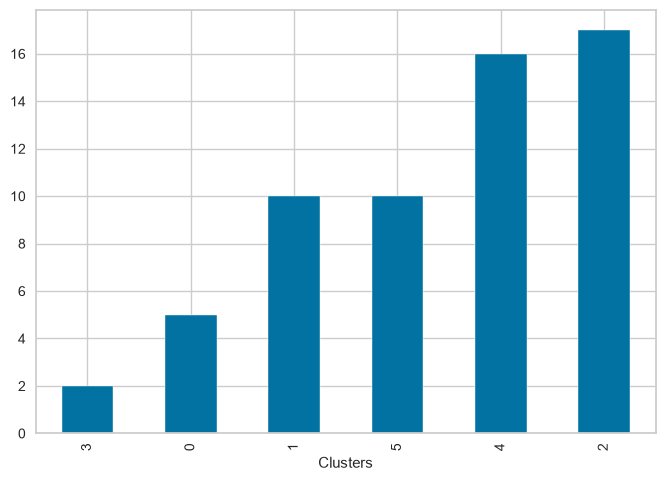

In [ ]:
print(f"* Clusters frequencies \n{ X['Clusters'].value_counts(normalize=True).to_frame().round(2)} \n\n")
X['Clusters'].value_counts().sort_values().plot(kind='bar')
plt.show()

## Compare current cluster predictions to previous cluster predictions

We just fitted a new cluster pipeline and want to compare if its predictions are "equivalent" to the previous cluster.

These are the predictions from the **previous** cluster pipeline - trained with all variables 

In [ ]:
cluster_predictions_with_all_variables

0     2
1     2
2     5
3     2
4     1
5     2
6     1
7     2
8     3
9     4
10    2
11    1
12    4
13    5
14    0
15    4
16    2
17    4
18    5
19    0
20    4
21    5
22    1
23    5
24    1
25    2
26    5
27    2
28    0
29    2
30    2
31    2
32    2
33    2
34    3
35    1
36    4
37    4
38    4
39    1
40    2
41    5
42    4
43    0
44    1
45    5
46    4
47    2
48    4
49    4
50    4
51    5
52    5
53    4
54    0
55    1
56    2
57    1
58    4
59    4
Name: Clusters, dtype: int32

And these are the predictions from **current** cluster pipeline (trained with `['OnlineBackup', 'MonthlyCharges', 'PhoneService']`)

In [ ]:
cluster_predictions_with_best_features = X['Clusters'] 
cluster_predictions_with_best_features

KeyError: 'Clusters'

We use a confusion matrix to evaluate if the predictions of both pipelines are **"equivalent"**

In [ ]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(cluster_predictions_with_all_variables, cluster_predictions_with_best_features))

NameError: name 'cluster_predictions_with_best_features' is not defined

## Fit a classifier, where the target is cluster predictions and features remaining variables

In [ ]:
df_clf = X.copy()
print(df_clf.shape)
df_clf.head(3)

(299, 1)


,DEATH_EVENT
0,1
1,1
2,1


Split Train and Test sets

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_clf.drop(['Clusters'], axis=1),
    df_clf['Clusters'],
    test_size=0.2,
    random_state=0
)

print(X_train.shape, X_test.shape)


KeyError: "['Clusters'] not found in axis"

Rewrite pipeline to explain clusters

In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

def PipelineClf2ExplainClusters():

    pipeline_base = Pipeline([
        ("model", GradientBoostingClassifier(
            random_state=0
        ))
    ])

    return pipeline_base

PipelineClf2ExplainClusters()



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required 

In [ ]:
from sklearn.model_selection import train_test_split

# Original clinical predictors
X = df.drop(columns=["DEATH_EVENT", "time"], errors="ignore")

# Cluster labels from your fitted KMeans pipeline
y_clusters = pipeline_cluster.predict(X)

# Split into training and test sets
X_train_cluster, X_test_cluster, y_train_cluster, y_test_cluster = train_test_split(
    X,
    y_clusters,
    test_size=0.2,
    random_state=0,
    stratify=y_clusters
)

# Initialize classifier
pipeline_clf_cluster = PipelineClf2ExplainClusters()

# Fit classifier
pipeline_clf_cluster.fit(X_train_cluster, y_train_cluster)

print("Classifier trained successfully")

Classifier trained successfully


## Fit a classifier, where the target is cluster labels and features remaining variables

Create and fit a classifier pipeline to learn the feature importance when defining a cluster

In [ ]:
pipeline_clf_cluster = PipelineClf2ExplainClusters()
pipeline_clf_cluster.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](6,)","[0,1,2,3,4,5]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','anaemia','creatinine_phosphokinase',...,'serum_sodium','sex', 'smoking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1


## Evaluate classifier performance on Train and Test Sets

In [ ]:
print(classification_report(y_train, pipeline_clf_cluster.predict(X_train)))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         6
           2       1.00      1.00      1.00        15
           3       1.00      1.00      1.00         1
           4       1.00      1.00      1.00        14
           5       1.00      1.00      1.00         8

    accuracy                           1.00        48
   macro avg       1.00      1.00      1.00        48
weighted avg       1.00      1.00      1.00        48



In [ ]:
print(classification_report(y_test, pipeline_clf_cluster.predict(X_test)))

              precision    recall  f1-score   support

           0       0.50      1.00      0.67         1
           1       1.00      0.25      0.40         4
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         1
           4       0.40      1.00      0.57         2
           5       0.00      0.00      0.00         2

    accuracy                           0.58        12
   macro avg       0.65      0.71      0.61        12
weighted avg       0.69      0.58      0.53        12



## Assess Most Important Features

* These are the 11 most important features in descending order. The model was trained on them: 
['sex', 'smoking', 'age', 'serum_sodium', 'high_blood_pressure', 'creatinine_phosphokinase', 'serum_creatinine', 'ejection_fraction', 'platelets', 'diabetes', 'anaemia']


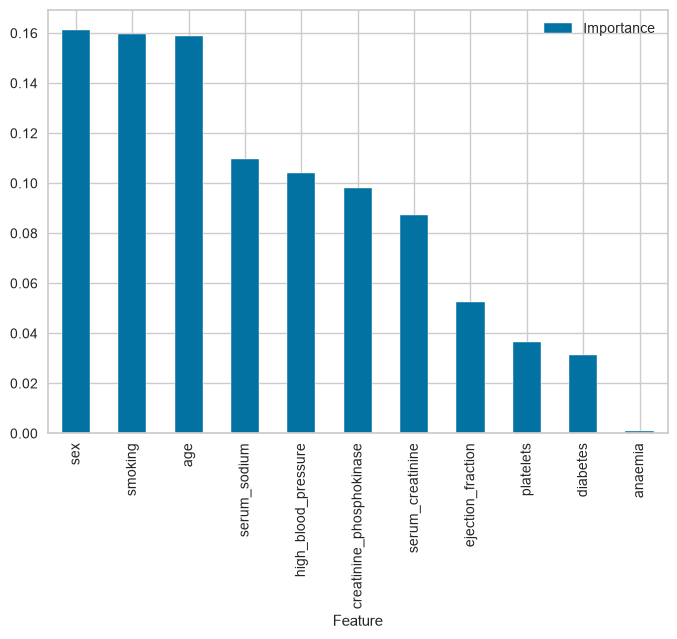

In [ ]:
# since we don't have feature selection step in this pipeline, best_features is Xtrain columns
best_features = X_train.columns.to_list()

# create a DataFrame to display feature importance
df_feature_importance = (pd.DataFrame(data={
    'Feature': best_features,
    'Importance': pipeline_clf_cluster['model'].feature_importances_})
    .sort_values(by='Importance', ascending=False)
)

best_features = df_feature_importance['Feature'].to_list()

# Most important features statement and plot
print(f"* These are the {len(best_features)} most important features in descending order. "
      f"The model was trained on them: \n{df_feature_importance['Feature'].to_list()}")

df_feature_importance.plot(kind='bar', x='Feature', y='Importance')
plt.show()


## Cluster Analysis

Create a DataFrame that contains the best features and Clusters Predictions: we want to analyse the patterns for each cluster.


In [ ]:
df_cluster_profile = df_clf.copy()
df_cluster_profile = df_cluster_profile.filter(items=best_features + ['Clusters'], axis=1)
df_cluster_profile.head(3)

,sex,smoking,age,serum_sodium,high_blood_pressure,creatinine_phosphokinase,serum_creatinine,ejection_fraction,platelets,diabetes,anaemia,Clusters
0,0,0,40.000,141,0,101,0.8,40,226000.0,0,1,2
1,0,0,60.667,136,1,151,1.0,40,201000.0,1,1,2
2,1,0,45.000,137,0,981,1.1,30,136000.0,0,1,5


We want also to analyse Churn levels

In [ ]:
import pandas as pd

df_reduced = pd.read_csv(r"C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\collection\HeartFailureData.csv"
).filter(["DEATH_EVENT"])

df_reduced["DEATH_EVENT"] = df_reduced["DEATH_EVENT"].astype("category")

df_reduced.head(3)

,DEATH_EVENT
0,1
1,1
2,1


In [ ]:
X_cluster = df.drop(
    columns=["DEATH_EVENT", "time"],
    errors="ignore"
)

df_reduced = pd.DataFrame({
    "Cluster": pipeline_cluster.predict(X_cluster)
})

df_reduced["Cluster"] = df_reduced["Cluster"].astype("category")

df_reduced.head(3)

,Cluster
0,2
1,2
2,5


In [ ]:
print("df columns:", df.columns.tolist())
print("df_reduced columns:", df_reduced.columns.tolist())

df columns: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
df_reduced columns: ['Cluster']


In [ ]:
df_original = pd.read_csv(
    r"C:\python_projects\Predictive_analysis\inputs\Data_set\heart_failure_clinical_records_dataset.csv"
)

print(df_original.columns.tolist())

df_reduced = df_original[["DEATH_EVENT"]].copy()

df_reduced["DEATH_EVENT"] = df_reduced["DEATH_EVENT"].astype("category")

display(df_reduced.head(3))

['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']


,DEATH_EVENT
0,1
1,1
2,1


### Cluster profile on most important features

In [ ]:
pd.set_option('display.max_colwidth', None)
clusters_profile = DescriptionAllClusters(df= pd.concat([df_cluster_profile,df_reduced], axis=1), decimal_points=0)
clusters_profile

,sex,smoking,age,serum_sodium,high_blood_pressure,creatinine_phosphokinase,serum_creatinine,ejection_fraction,platelets,diabetes,anaemia
Cluster,,,,,,,,,,,
5,1.0 -- 1.0,0.0 -- 0.0,46.0 -- 55.0,138.0 -- 140.0,0.0 -- 1.0,282.0 -- 1900.0,1.0 -- 1.0,25.0 -- 34.0,137250.0 -- 222250.0,0.0 -- 0.0,0.0 -- 1.0
4,1.0 -- 1.0,1.0 -- 1.0,54.0 -- 68.0,135.0 -- 137.0,0.0 -- 0.0,292.0 -- 795.0,1.0 -- 1.0,35.0 -- 45.0,259500.0 -- 306250.0,0.0 -- 1.0,0.0 -- 0.0
3,0.0 -- 0.0,0.0 -- 0.0,56.0 -- 58.0,139.0 -- 144.0,0.0 -- 1.0,1311.0 -- 3080.0,7.0 -- 8.0,64.0 -- 68.0,179090.0 -- 235269.0,0.0 -- 1.0,0.0 -- 1.0
2,0.0 -- 0.0,0.0 -- 0.0,45.0 -- 65.0,136.0 -- 139.0,0.0 -- 0.0,101.0 -- 582.0,1.0 -- 1.0,38.0 -- 60.0,222000.0 -- 271000.0,1.0 -- 1.0,0.0 -- 1.0
1,0.0 -- 1.0,0.0 -- 0.0,66.0 -- 88.0,132.0 -- 135.0,0.0 -- 1.0,126.0 -- 377.0,1.0 -- 2.0,30.0 -- 40.0,178750.0 -- 236500.0,0.0 -- 0.0,0.0 -- 1.0
0,1.0 -- 1.0,1.0 -- 1.0,62.0 -- 68.0,140.0 -- 142.0,1.0 -- 1.0,94.0 -- 220.0,1.0 -- 1.0,30.0 -- 38.0,188000.0 -- 289000.0,1.0 -- 1.0,0.0 -- 1.0


### Clusters distribution across Churn levels & Relative Percentage of Churn in each cluster

## Which pipeline should I deploy?

Let's recap the criteria we consider to evaluate the **trade-off**
1. Conduct an elbow method and silhouette analysis and check if the same number of clusters is suggested.
2. Fit a new cluster pipeline and compare if the predictions from this pipeline are "equivalent" to the predictions from the previous pipeline.
3. Fit a classifier to explain cluster and check if performance on Train and Test sets is similar to the previous pipeline.
4. Check if the most important features for the classifier are the same from the previous pipeline.
5. Compare if the cluster profile from both pipelines is "equivalent".


In [ ]:
pipeline_cluster

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('PCA', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','anaemia','creatinine_phosphokinase',...,'serum_sodium','sex', 'smoking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


# Push files to Repo


We will generate the following files

* Cluster Pipeline
* Train Set
* Feature importance plot
* Clusters Description
* Cluster Silhouette


In [ ]:
import joblib
import os

version = 'v1'
file_path = f'outputs/ml_pipeline/cluster_analysis/{version}'

try:
    os.makedirs(name=file_path)
except Exception as e:
    print(e)


[WinError 183] Det går inte att skapa en fil som redan finns: 'outputs/ml_pipeline/cluster_analysis/v1'


## Cluster pipeline

In [ ]:
pipeline_cluster

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('PCA', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','anaemia','creatinine_phosphokinase',...,'serum_sodium','sex', 'smoking']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [ ]:
joblib.dump(value=pipeline_cluster, filename=f"{file_path}/cluster_pipeline.pkl")

['outputs/ml_pipeline/cluster_analysis/v1/cluster_pipeline.pkl']

## Train Set

In [ ]:
print(df_reduced.shape)
df_reduced.head(3)

(60, 1)


,Cluster
0,2
1,2
2,5


In [ ]:
df_reduced.to_csv(f"{file_path}/TrainSet.csv", index=False)

## Most important features plot

These are the features that define a cluster

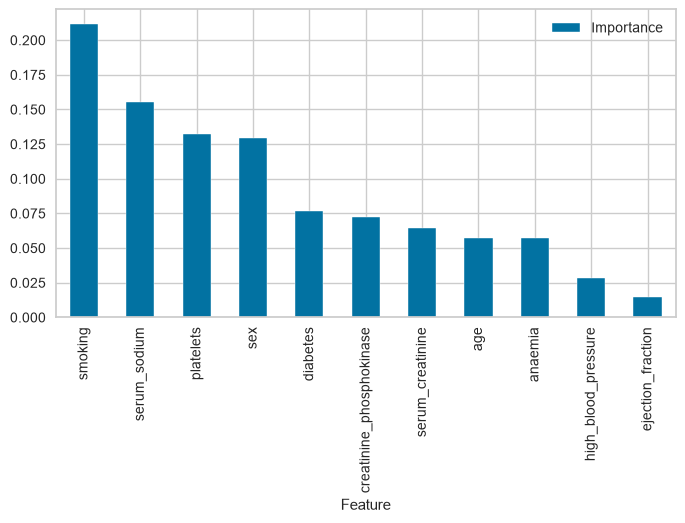

In [ ]:
df_feature_importance.plot(kind='bar',x='Feature',y='Importance', figsize=(8,4))
plt.show()

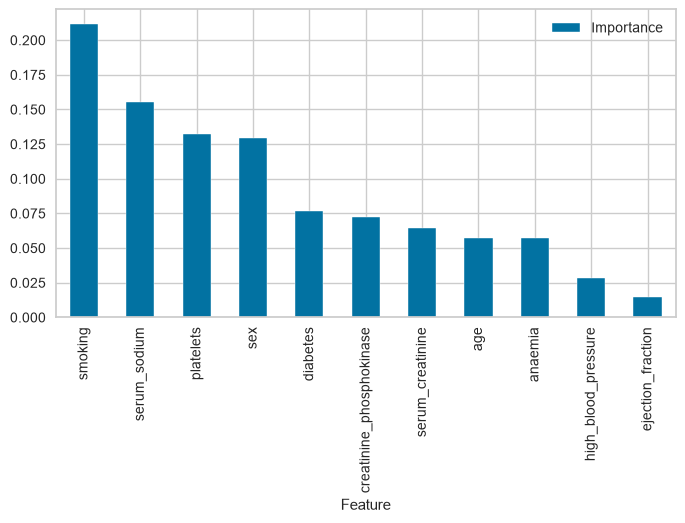

In [ ]:
df_feature_importance.plot(kind='bar',x='Feature',y='Importance', figsize=(8,4))
plt.savefig(f"{file_path}/features_define_cluster.png", bbox_inches='tight', dpi=150)

## Cluster Profile

In [ ]:
clusters_profile

,smoking,serum_sodium,platelets,sex,diabetes,creatinine_phosphokinase,serum_creatinine,age,anaemia,high_blood_pressure,ejection_fraction
Cluster,,,,,,,,,,,
4,0.0 -- 0.0,139.0 -- 144.0,179090.0 -- 235269.0,0.0 -- 0.0,0.0 -- 1.0,1311.0 -- 3080.0,7.0 -- 8.0,56.0 -- 58.0,0.0 -- 1.0,0.0 -- 1.0,64.0 -- 68.0
3,0.0 -- 0.0,130.0 -- 134.0,217000.0 -- 263358.0,0.0 -- 1.0,0.0 -- 0.0,207.0 -- 582.0,2.0 -- 2.0,60.0 -- 73.0,0.0 -- 0.0,0.0 -- 0.0,30.0 -- 40.0
2,0.0 -- 1.0,137.0 -- 140.0,137250.0 -- 209250.0,1.0 -- 1.0,0.0 -- 0.0,115.0 -- 531.0,1.0 -- 1.0,50.0 -- 66.0,0.0 -- 1.0,0.0 -- 1.0,26.0 -- 37.0
1,0.0 -- 0.0,136.0 -- 140.0,213000.0 -- 271000.0,0.0 -- 0.0,1.0 -- 1.0,96.0 -- 270.0,1.0 -- 1.0,50.0 -- 65.0,0.0 -- 1.0,0.0 -- 1.0,38.0 -- 60.0
0,1.0 -- 1.0,135.0 -- 137.0,250250.0 -- 304750.0,1.0 -- 1.0,0.0 -- 1.0,372.0 -- 1298.0,1.0 -- 1.0,51.0 -- 66.0,0.0 -- 0.0,0.0 -- 0.0,31.0 -- 45.0


In [ ]:
clusters_profile.to_csv(f"{file_path}/clusters_profile.csv")

## Cluster silhouette plot

=== Average Silhouette Score ===
2 clusters: 0.1910


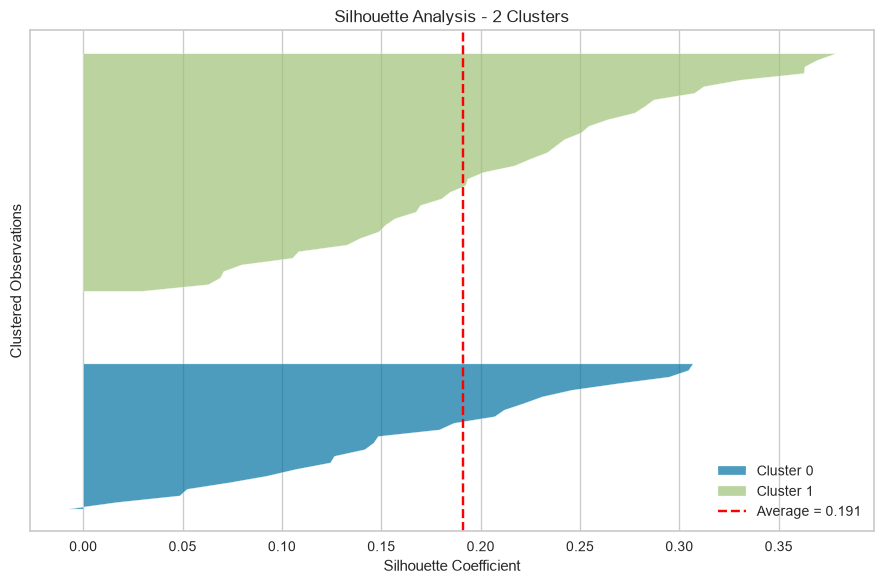

3 clusters: 0.1683


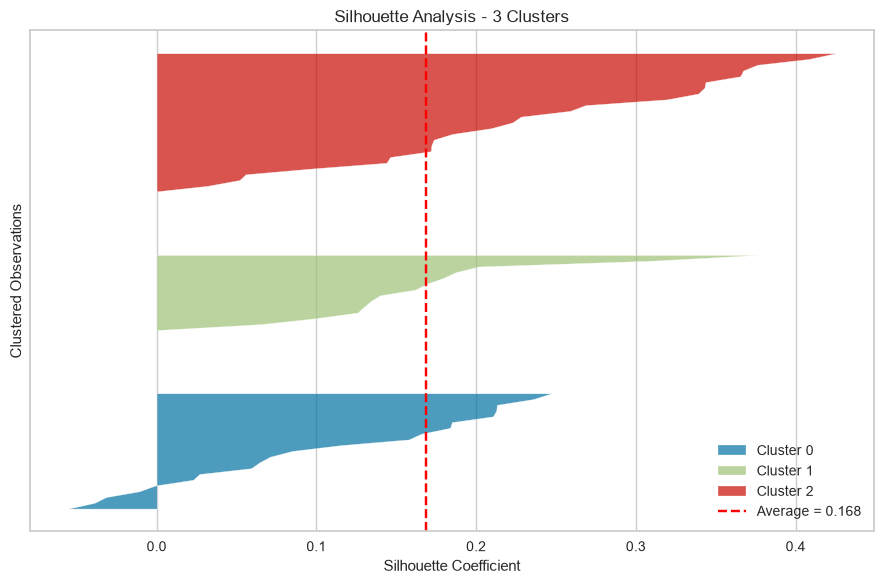

4 clusters: 0.1874


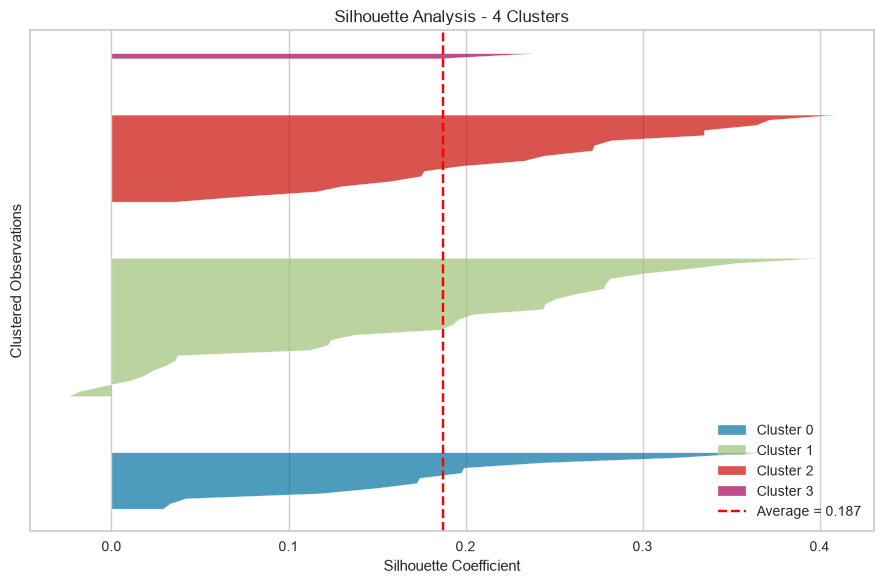

5 clusters: 0.1940


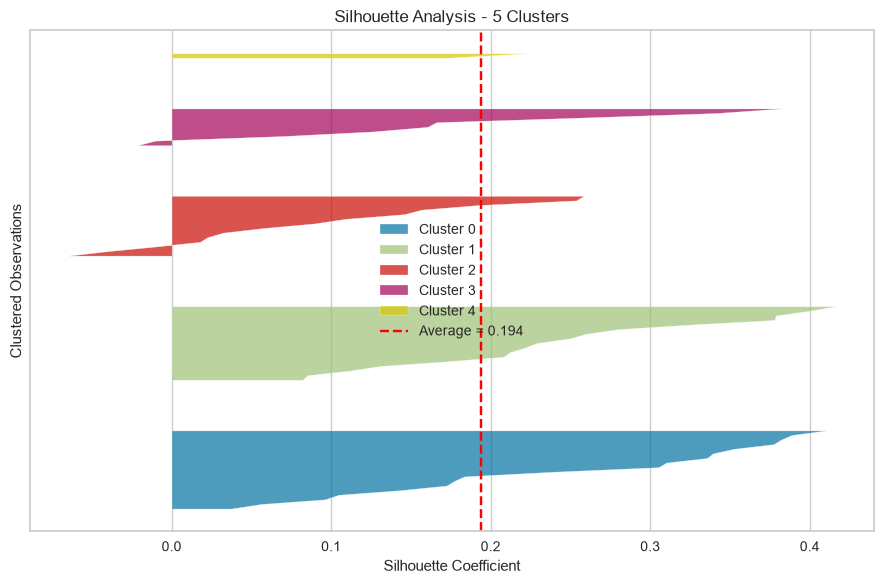

,Clusters,Silhouette Score
0,2,0.191013
1,3,0.168314
2,4,0.187432
3,5,0.193951


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Use your existing PCA-transformed data
X = np.asarray(df_analysis)

n_cluster_start = 2
n_cluster_stop = 6

results = []

print("=== Average Silhouette Score ===")

for n_clusters in range(n_cluster_start, n_cluster_stop):

    model = KMeans(
        n_clusters=n_clusters,
        random_state=0,
        n_init=10
    )

    cluster_labels = model.fit_predict(X)

    # Average silhouette score
    avg_score = silhouette_score(X, cluster_labels)

    results.append({
        "Clusters": n_clusters,
        "Silhouette Score": avg_score
    })

    print(f"{n_clusters} clusters: {avg_score:.4f}")

    # Silhouette values for individual observations
    sample_scores = silhouette_samples(X, cluster_labels)

    fig, ax = plt.subplots(figsize=(9, 6))

    y_lower = 10

    for i in range(n_clusters):

        cluster_scores = sample_scores[
            cluster_labels == i
        ]

        cluster_scores.sort()

        cluster_size = len(cluster_scores)
        y_upper = y_lower + cluster_size

        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            cluster_scores,
            alpha=0.7,
            label=f"Cluster {i}"
        )

        y_lower = y_upper + 10

    # Average silhouette score reference
    ax.axvline(
        x=avg_score,
        color="red",
        linestyle="--",
        label=f"Average = {avg_score:.3f}"
    )

    ax.set_title(
        f"Silhouette Analysis - {n_clusters} Clusters"
    )
    ax.set_xlabel("Silhouette Coefficient")
    ax.set_ylabel("Clustered Observations")
    ax.set_yticks([])
    ax.legend()

    plt.tight_layout()
    plt.show()

# Display summary
results_df = pd.DataFrame(results)

display(results_df)


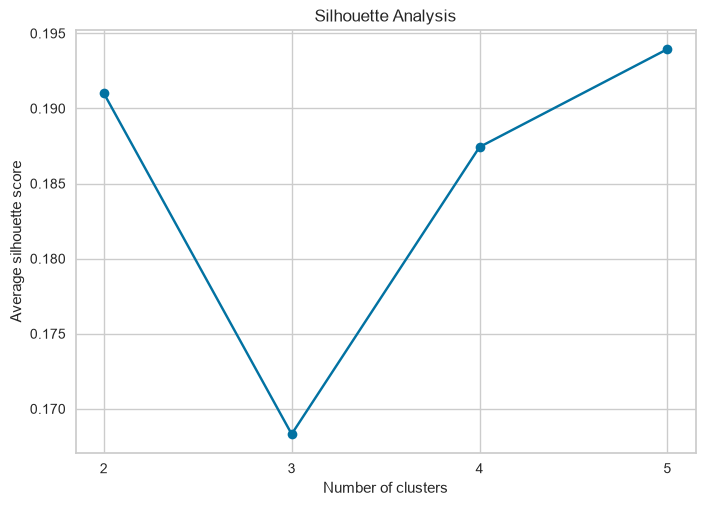

Best number of clusters: 5


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

scores = []

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = model.fit_predict(df_analysis)
    scores.append(silhouette_score(df_analysis, labels))

plt.plot(range(2, 6), scores, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Average silhouette score")
plt.title("Silhouette Analysis")
plt.xticks(range(2, 6))
plt.show()

best_k = range(2, 6)[scores.index(max(scores))]
print("Best number of clusters:", best_k)

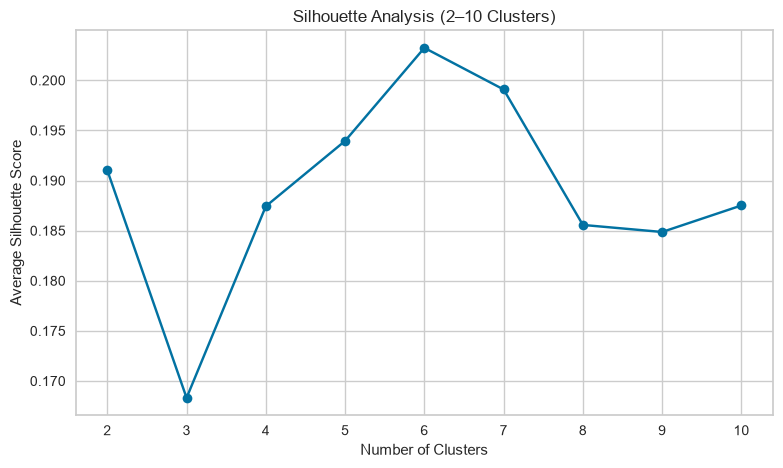

Optimal number of clusters: 6
Best silhouette score: 0.2032


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

scores = []

cluster_range = range(2, 11)

for k in cluster_range:
    model = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=10
    )

    labels = model.fit_predict(df_analysis)
    score = silhouette_score(df_analysis, labels)
    scores.append(score)

plt.figure(figsize=(9, 5))
plt.plot(cluster_range, scores, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Average Silhouette Score")
plt.title("Silhouette Analysis (2–10 Clusters)")
plt.xticks(list(cluster_range))
plt.grid(True)
plt.show()

best_k = list(cluster_range)[scores.index(max(scores))]

print("Optimal number of clusters:", best_k)
print("Best silhouette score:", round(max(scores), 4))

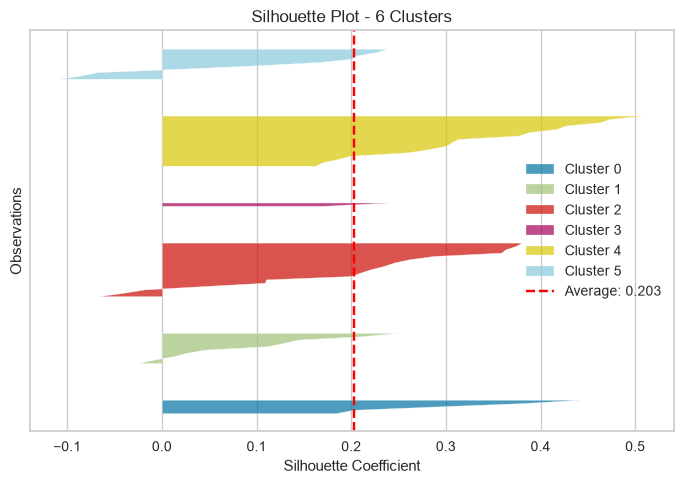

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import silhouette_samples, silhouette_score

# Cluster labels from the fitted KMeans model
cluster_labels = pipeline_cluster["model"].labels_

# Number of clusters
n_clusters = pipeline_cluster["model"].n_clusters

# Calculate silhouette scores
silhouette_values = silhouette_samples(
    df_analysis,
    cluster_labels
)

average_score = silhouette_score(
    df_analysis,
    cluster_labels
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 5))

y_lower = 10

for cluster_id in range(n_clusters):

    values = silhouette_values[
        cluster_labels == cluster_id
    ]

    values.sort()

    cluster_size = len(values)
    y_upper = y_lower + cluster_size

    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0,
        values,
        alpha=0.7,
        label=f"Cluster {cluster_id}"
    )

    y_lower = y_upper + 10

# Average silhouette score
ax.axvline(
    average_score,
    color="red",
    linestyle="--",
    label=f"Average: {average_score:.3f}"
)

ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Observations")
ax.set_title(f"Silhouette Plot - {n_clusters} Clusters")
ax.set_yticks([])
ax.legend()

plt.tight_layout()

# Save figure
file_path = Path("outputs/figures")
file_path.mkdir(parents=True, exist_ok=True)

fig.savefig(
    file_path / "clusters_silhouette.png",
    bbox_inches="tight",
    dpi=150
)

plt.show()


Good job, clear the cell outputs, run git commands to add, commit and push files to the repo. Next, we will move on to create our dashboard!

In [ ]:
from sklearn.base import clone
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for k in [4, 5, 6]:
    pipeline = clone(pipeline_cluster)
    pipeline.set_params(model__n_clusters=k)

    labels = pipeline.fit_predict(X_cluster)

    # Evaluate in the same PCA space used by K-Means
    X_pca = pipeline[:-1].transform(X_cluster)

    score = silhouette_score(X_pca, labels)

    results.append({
        "Clusters": k,
        "Silhouette Score": score
    })

results_df = pd.DataFrame(results)
display(results_df)

NameError: name 'pipeline_cluster' is not defined